# Text-to-Video Search

The chapter opens with two requests to "Tears of Steel". The first is the scene in which Celia
accuses Thom of being afraid of her robot hand: the subtitles contain the line. The second is the
fight against the robots: it is shown, not said. This notebook follows the book section *Video
Understanding with Transformers* and builds a small index of moments for the film: one entry per
shot, with CLIP embeddings of its frames, its subtitles, and its motion. We compare a middle
keyframe with mean pooling, search the subtitles with BM25, and fuse the rankings with reciprocal
rank fusion. At the end, one index answers both requests with clips whose edges are shot
boundaries.

**Learning goals:**
- Build an index of moments from the shots, the frames, and the subtitles of a video
- Reproduce the book's toy comparison of a keyframe, mean pooling, and the best single frame
- Search shots with CLIP, measure the result against the fight sequences, and see how small the
  score differences are
- Search the subtitles with BM25 and turn the hits into clips
- Fuse several rankings with reciprocal rank fusion, and see when fusion helps and when it hurts

**Prerequisites:** demos ch12-01 (shots) and ch12-02 (motion); Chapter 10, section on learned
features (CLIP); Chapter 5 (reciprocal rank fusion)

**Data:** "Tears of Steel" by the Blender Foundation (mango.blender.org), CC BY 3.0, and its
English subtitles, downloaded on first run to `data/tears_of_steel/`. CLIP ViT-B/32
(`openai/clip-vit-base-patch32`, about 600 MB) is downloaded from Hugging Face on first use.

**Run time:** about half a minute with the caches of ch12-01 and ch12-02. The first run embeds
about 870 frames with CLIP on the CPU (a few minutes); the embeddings are cached.

## Setup

`ch12_video.py` holds the plumbing: the TransNet V2 shots of ch12-01, the motion measurements of
ch12-02, the subtitles, the CLIP model, and the fight sequences of the film. Pooling, BM25 over the
subtitles, fusion, and the clips are computed in this notebook.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

from shared.display import print_table, display_md
from shared.retrieval import document_frequencies, rank_collection_bm25, idf_lucene
from shared.text import remove_stopwords
from ch12_video import (FPS, N_FRAMES, ensure_film, frames, tc, transnet_probabilities,
                        transnet_transitions, shots_from_transitions, parse_srt, Clip,
                        clip_frame_embeddings, shot_activity, is_fight, show_frames)

ensure_film()
p, _ = transnet_probabilities()                         # cached by ch12-01
shots = shots_from_transitions(transnet_transitions(p))
subtitles = parse_srt()
clip = Clip()
sampled, sampled_emb, middles, middle_emb = clip_frame_embeddings(shots, clip)    # cached after the first run

## 1. An Index of Moments

Each entry of the index is a shot with its start and end time. We attach three things to it: the
CLIP embeddings of the frames sampled at one per second, the subtitles that overlap the shot, and
the share of moving pixels from demo ch12-02.

In [2]:
shot_of_frame = np.zeros(N_FRAMES, int)
for k, (a, b) in enumerate(shots):
    shot_of_frame[a:b + 1] = k

frames_of_shot = [[] for _ in shots]                    # indices into sampled / sampled_emb
for i, t in enumerate(sampled):
    frames_of_shot[shot_of_frame[t]].append(i)

def overlaps(a, b, start_s, end_s):
    """Does the shot of frames a..b overlap the time span start_s..end_s (seconds)?"""
    return a <= end_s * FPS and b >= start_s * FPS

subs_of_shot = [[i for i, (s, e, _) in enumerate(subtitles) if overlaps(a, b, s, e)] for a, b in shots]
shots_of_sub = [[k for k, (a, b) in enumerate(shots) if overlaps(a, b, s, e)] for s, e, _ in subtitles]
activity = shot_activity(shots)                         # from ch12-02, cached
fight = np.array([is_fight(a, b) for a, b in shots])    # the three fight sequences of the book

index = [dict(shot=k, start=a, end=b, frames=frames_of_shot[k], subtitles=subs_of_shot[k],
              activity=activity[k], fight=fight[k]) for k, (a, b) in enumerate(shots)]

print_table([[m["shot"], tc(m["start"]), tc(m["end"]), len(m["frames"]), m["activity"],
              " / ".join(subtitles[i][2] for i in m["subtitles"])[:70]] for m in index[1:9]],
            ["Shot", "Start", "End", "Frames", "Motion", "Subtitles"], floatfmt=("", "", "", "", ".2f", ""))
lengths = np.array([(b - a + 1) / FPS for a, b in shots])
display_md(
    f"{len(index)} shots, {lengths.mean():.1f} seconds on average (median {np.median(lengths):.1f}). "
    f"{len(sampled)} sampled frames, at least one in every shot: "
    f"{min(len(m['frames']) for m in index)} to {max(len(m['frames']) for m in index)} per shot. "
    f"{sum(bool(m['subtitles']) for m in index)} shots overlap a subtitle, and "
    f"{fight.sum()} shots belong to a fight sequence."
)

|   Shot | Start   | End     |   Frames |   Motion | Subtitles                                                              |
|-------:|:--------|:--------|---------:|---------:|:-----------------------------------------------------------------------|
|      1 | 0:08.92 | 0:13.42 |        4 |     0.10 |                                                                        |
|      2 | 0:13.46 | 0:18.38 |        5 |     0.06 |                                                                        |
|      3 | 0:18.42 | 0:24.96 |        7 |     0.01 | You're a jerk, Thom.                                                   |
|      4 | 0:25.00 | 0:40.21 |       15 |     0.01 | Look Celia, we have to follow our passions; / ...you have your robotic |
|      5 | 0:40.25 | 0:42.04 |        2 |     0.03 | I'm freaked out! I have nightmares that I'm being chased... / ...by th |
|      6 | 0:42.08 | 0:45.58 |        4 |     0.00 | "Fourty years later" Whatever, Thom. We're done.                       |
|      7 | 0:45.62 | 0:49.75 |        4 |     0.17 |                                                                        |
|      8 | 0:49.79 | 0:51.08 |        1 |     0.16 | Robot's memory synced and locked!                                      |

140 shots, 5.2 seconds on average (median 3.2). 734 sampled frames, at least one in every shot: 1 to 88 per shot. 67 shots overlap a subtitle, and 34 shots belong to a fight sequence.

## 2. Keyframe versus Mean Pooling

### The book's toy example

The book embeds three frames of one shot in three dimensions that stand for "street", "bridge",
and "robot", and scores two queries with three strategies: the middle keyframe, the mean of the
frame embeddings, and the best single frame.

In [3]:
def cosine(q, v):
    return float(q @ v / (np.linalg.norm(q) * np.linalg.norm(v)))

toy = np.array([[0.8, 0.6, 0.0],        # a street
                [0.6, 0.8, 0.0],        # the bridge
                [0.0, 0.6, 0.8]])       # a robot on the bridge
rows = []
for name, q in [("a robot", np.array([0, 0, 1.0])), ("a bridge", np.array([0, 1.0, 0]))]:
    rows.append([name, cosine(q, toy[1]), cosine(q, toy.mean(axis=0)), max(cosine(q, e) for e in toy)])
print_table(rows, ["Query", "Middle keyframe", "Mean pooling", "Best single frame"], floatfmt=".3f")

| Query    |   Middle keyframe |   Mean pooling |   Best single frame |
|:---------|------------------:|---------------:|--------------------:|
| a robot  |             0.000 |          0.311 |               0.800 |
| a bridge |             0.800 |          0.778 |               0.800 |

The middle keyframe makes the robot invisible; mean pooling keeps a weaker trace of it and scores
the main content almost as well as the keyframe.

### The three strategies on the film

For a real query, we embed the text with CLIP and score every shot three ways. The middle frames
were embedded separately, so the keyframe strategy does not depend on the sampling.

In [4]:
def shot_scores(query):
    """Cosine scores of all shots for a text query: middle keyframe, mean-pooled frames, best frame."""
    q = clip.text(query)
    keyframe = middle_emb @ q
    mean = np.array([cosine(q, sampled_emb[ix].mean(axis=0)) for ix in frames_of_shot])
    best = np.array([(sampled_emb[ix] @ q).max() for ix in frames_of_shot])
    return dict(keyframe=keyframe, mean=mean, best=best)

def top(scores, n=5):
    return list(np.argsort(-scores)[:n])

query = "a battle against giant robots"
scores = shot_scores(query)
print_table([[r + 1] + [f"{tc(shots[k][0])}{' (fight)' if fight[k] else ''}  {scores[s][k]:.3f}"
                        for s, k in ((s, top(scores[s])[r]) for s in scores)] for r in range(5)],
            ["Rank", "Middle keyframe", "Mean pooling", "Best single frame"])

|   Rank | Middle keyframe        | Mean pooling           | Best single frame      |
|-------:|:-----------------------|:-----------------------|:-----------------------|
|      1 | 3:42.42  0.273         | 9:57.62  0.287         | 7:53.12 (fight)  0.291 |
|      2 | 9:34.79 (fight)  0.272 | 3:42.42  0.282         | 9:48.00  0.283         |
|      3 | 1:42.42 (fight)  0.270 | 7:44.83 (fight)  0.282 | 7:44.83 (fight)  0.280 |
|      4 | 7:49.54 (fight)  0.270 | 9:34.79 (fight)  0.281 | 5:30.29  0.280         |
|      5 | 5:30.29  0.270         | 9:48.00  0.280         | 9:34.79 (fight)  0.280 |

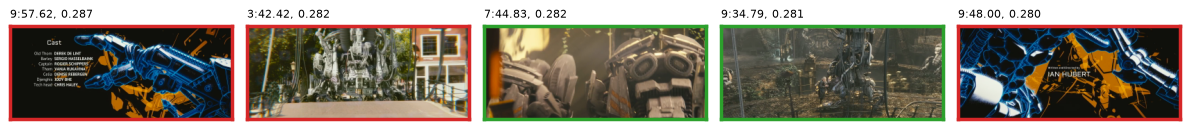

In [5]:
best5 = top(scores["mean"])
show_frames([frames(int(middles[k]), 1)[0] for k in best5],
            [f"{tc(shots[k][0])}, {scores['mean'][k]:.3f}" for k in best5],
            ncols=5, width=2.4, colors=["tab:green" if fight[k] else "tab:red" for k in best5])

Green frames mark fight shots. The best shot of mean pooling comes from the end credits, which show
drawn robots. We count the fight shots among the five best shots of each strategy, for the three
queries of the book.

In [6]:
queries = ["a battle against giant robots", "soldiers fight robots", "a fight against a robot"]
rows = []
for q in queries:
    sc = shot_scores(q)
    rows.append([q] + [int(fight[top(sc[s])].sum()) for s in ("keyframe", "mean", "best")]
                + [f"{min(sc['mean'][top(sc['mean'])]):.3f} to {max(sc['mean']):.3f}",
                   f"{np.median(sc['mean']):.3f}"])
print_table(rows, ["Query", "Keyframe", "Mean", "Best frame", "Top-5 scores (mean)", "Median shot"])
display_md(f"For comparison: a random choice of five shots contains {5 * fight.mean():.1f} fight shots on average.")

| Query                         |   Keyframe |   Mean |   Best frame | Top-5 scores (mean)   |   Median shot |
|:------------------------------|-----------:|-------:|-------------:|:----------------------|--------------:|
| a battle against giant robots |          3 |      2 |            3 | 0.280 to 0.287        |         0.233 |
| soldiers fight robots         |          0 |      0 |            0 | 0.259 to 0.264        |         0.212 |
| a fight against a robot       |          0 |      0 |            1 | 0.268 to 0.275        |         0.226 |

For comparison: a random choice of five shots contains 1.2 fight shots on average.

All scores lie close together: the fifth-best shot and the median shot differ by a few hundredths.
CLIP recognizes robots, but not a fight, and the wording of the query changes the result more than
the pooling does. The shots are short, so mean pooling has only a few frames to combine.

## 3. Searching the Subtitles

Words that are spoken are found in the subtitles. We treat each of the 76 subtitles as a document,
split it into lowercase words, remove stopwords, and rank with BM25 (the variant with the
Lucene IDF, which stays positive in small collections).

In [7]:
def words(text):
    return remove_stopwords(re.findall(r"[a-z']+", text.lower()))

sub_docs = {i: words(text) for i, (_, _, text) in enumerate(subtitles)}
sub_df = document_frequencies(sub_docs)

def subtitle_hits(query):
    """Subtitles with a positive BM25 score, best first: (subtitle index, score)."""
    return [(i, s) for i, s in rank_collection_bm25(words(query), sub_docs, sub_df, idf_fn=idf_lucene) if s > 0]

rows = []
for i, s in subtitle_hits("robot hand"):
    start_s, end_s, text = subtitles[i]
    rows.append([f"{tc(int(start_s * FPS))} to {tc(int(end_s * FPS))}", f"{s:.2f}", text,
                 ", ".join(f"{tc(shots[k][0])} to {tc(shots[k][1])}" for k in shots_of_sub[i])])
print_table(rows, ["Subtitle", "BM25", "Text", "Shots"])

| Subtitle           |   BM25 | Text                                                               | Shots                                  |
|:-------------------|-------:|:-------------------------------------------------------------------|:---------------------------------------|
| 0:30.79 to 0:34.00 |   5.06 | Why don't you just admit that you're freaked out by my robot hand? | 0:25.00 to 0:40.21                     |
| 5:47.00 to 5:50.00 |   5.06 | Why don't you just admit that you're freaked out by my robot hand? | 5:46.46 to 5:48.38, 5:48.42 to 5:50.17 |

The two hits are the line at 0:30.8 and its replay at 5:47.0; no other subtitle contains "robot"
or "hand". The second line crosses a cut, so its clip will join two shots. Does CLIP find these
shots if we use the spoken line as a visual query?

In [8]:
line = subtitles[subtitle_hits("robot hand")[0][0]][2]
sc = shot_scores(line)["mean"]
ranking = list(np.argsort(-sc))
targets = sorted({k for i, _ in subtitle_hits("robot hand") for k in shots_of_sub[i]})   # shots with the line
display_md(f"CLIP query: *{line}*\n\n"
           f"Ranks of the {len(targets)} shots with this line among {len(shots)}: "
           + ", ".join(f"shot {tc(shots[k][0])}: rank {ranking.index(k) + 1}" for k in targets)
           + f". The top shot is {tc(shots[ranking[0]][0])}.")

CLIP query: *Why don't you just admit that you're freaked out by my robot hand?*

Ranks of the 3 shots with this line among 140: shot 0:25.00: rank 37, shot 5:46.46: rank 102, shot 5:48.42: rank 39. The top shot is 6:28.96.

What is said is not visible in the frames. And the subtitles mislead the visual query: the words
of the fight query match lines that are spoken far from any fight.

In [9]:
print_table([[f"{tc(int(subtitles[i][0] * FPS))}", f"{s:.2f}", subtitles[i][2],
              "yes" if any(fight[k] for k in shots_of_sub[i]) else "no"] for i, s in subtitle_hits(query)],
            ["Subtitle", "BM25", "Text", "In a fight shot"])

| Subtitle   |   BM25 | Text                                        | In a fight shot   |
|:-----------|-------:|:--------------------------------------------|:------------------|
| 0:41.00    |   2.91 | ...by these giant robotic claws of death... | no                |

## 4. Fusing the Rankings

Reciprocal rank fusion gives each shot the sum of $1 / (k + \text{rank})$ over the rankings in
which it appears, with $k = 60$. It needs no calibration of the scores, which matters here: BM25
scores, cosine similarities, and shares of moving pixels have nothing in common but their order.

In [10]:
def rrf(*rankings, k=60):
    """Reciprocal rank fusion of rankings (lists of shot ids, best first)."""
    score = {}
    for ranking in rankings:
        for rank, shot in enumerate(ranking, start=1):
            score[shot] = score.get(shot, 0.0) + 1 / (k + rank)
    return sorted(score, key=lambda s: -score[s])

def rankings(query):
    """The three fields of the index as rankings of shots."""
    by_sub = {}
    for i, s in subtitle_hits(query):
        for k in shots_of_sub[i]:
            by_sub[k] = max(by_sub.get(k, 0.0), s)
    return dict(subtitles=sorted(by_sub, key=lambda k: -by_sub[k]),
                clip=list(np.argsort(-shot_scores(query)["mean"])),
                motion=list(np.argsort(-activity)))

We compare single fields and fusions on the fight queries (fight shots among the top 5 and the top
10) and on "robot hand" (the rank of the first shot with the line).

In [11]:
combos = [("subtitles",), ("clip",), ("motion",), ("subtitles", "clip"), ("clip", "motion"),
          ("subtitles", "clip", "motion")]
rows = []
for q in queries + ["robot hand"]:
    r = rankings(q)
    row = [q]
    for combo in combos:
        fused = rrf(*(r[c] for c in combo))
        if q == "robot hand":
            row.append(next((i + 1 for i, k in enumerate(fused) if k in targets), "none"))
        else:
            row.append(f"{int(fight[fused[:5]].sum())} / {int(fight[fused[:10]].sum())}")
    rows.append(row)
print_table(rows, ["Query"] + [" + ".join(c) for c in combos])
display_md("Fight queries: fight shots among the top 5 / top 10. \"robot hand\": rank of the first shot with the line.")

| Query                         | subtitles   | clip   | motion   | subtitles + clip   | clip + motion   | subtitles + clip + motion   |
|:------------------------------|:------------|:-------|:---------|:-------------------|:----------------|:----------------------------|
| a battle against giant robots | 0 / 0       | 2 / 4  | 5 / 10   | 2 / 4              | 3 / 6           | 3 / 5                       |
| soldiers fight robots         | 0 / 0       | 0 / 1  | 5 / 10   | 0 / 1              | 4 / 5           | 4 / 5                       |
| a fight against a robot       | 0 / 0       | 0 / 0  | 5 / 10   | 0 / 0              | 3 / 6           | 2 / 4                       |
| robot hand                    | 1           | 35     | 107      | 1                  | 73              | 1                           |

Fight queries: fight shots among the top 5 / top 10. "robot hand": rank of the first shot with the line.

The table shows what each field contributes:

- **Motion alone** puts five fight shots in the top 5 for every fight query. In this film, the
  fights are the shots with the most motion. But motion ignores the words of the query: it returns
  the same shots for "robot hand", where the first shot with the line comes far down the list.
- **CLIP alone** finds what the query describes, but on the fight queries it finds few fight shots.
  Fused with motion, it finds more fight shots than alone: shots that look like the query and move
  a lot rise to the top.
- **The subtitles** answer the spoken line at rank 1, alone and in every fusion that includes them.
  For the fight queries they add nothing or hurt: their words match the dialogue lines about robots.

A field helps only when it fits the query. A real system decides per query which fields to
search, or it lets a filter such as "much motion" apply only to action queries.

## Payoff: One Index, Two Requests

We answer the two requests of the chapter opener with the fields that fit them: the spoken line
with the subtitles and CLIP, the fight with CLIP and motion. Adjacent shots in the result merge
into one clip, so a clip starts and ends at shot boundaries.

| Clip               | Length   |   Shots | Relevant   |
|:-------------------|:---------|--------:|:-----------|
| 0:25.00 to 0:40.21 | 15.2 s   |       1 | yes        |
| 5:46.46 to 5:50.17 | 3.8 s    |       2 | yes        |

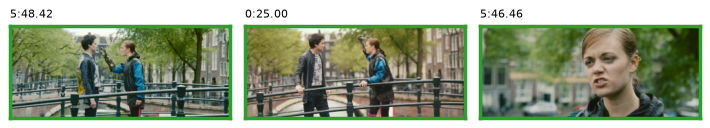

**robot hand** with subtitles + clip: the 3 best shots form 2 clip(s).

| Clip               | Length   |   Shots | Relevant   |
|:-------------------|:---------|--------:|:-----------|
| 3:28.67 to 3:32.42 | 3.8 s    |       1 | no         |
| 7:44.83 to 7:48.29 | 3.5 s    |       1 | yes        |
| 7:49.54 to 7:53.08 | 3.6 s    |       1 | yes        |
| 8:13.33 to 8:15.50 | 2.2 s    |       1 | yes        |
| 8:41.00 to 8:47.38 | 6.4 s    |       1 | no         |

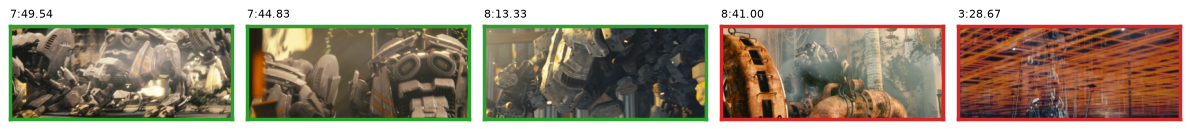

**a battle against giant robots** with clip + motion: the 5 best shots form 5 clip(s).

In [12]:
def clips(shot_ids):
    """Merge shots that follow each other into clips (first frame, last frame, number of shots)."""
    out = []
    for k in sorted(shot_ids):
        if out and k == out[-1][2] + 1:
            out[-1][1], out[-1][2] = shots[k][1], k
            out[-1][3] += 1
        else:
            out.append([shots[k][0], shots[k][1], k, 1])
    return [(a, b, n) for a, b, _, n in out]

def answer(query, fields, n=5):
    r = rankings(query)
    best = rrf(*(r[f] for f in fields))[:n]
    return best, clips(best)

for query, fields, n in [("robot hand", ("subtitles", "clip"), 3),
                         ("a battle against giant robots", ("clip", "motion"), 5)]:
    best, result = answer(query, fields, n)
    relevant = (lambda k: k in targets) if query == "robot hand" else (lambda k: fight[k])
    print_table([[f"{tc(a)} to {tc(b)}", f"{(b - a + 1) / FPS:.1f} s", m,
                  "yes" if any(relevant(k) for k in best if a <= shots[k][0] <= b) else "no"] for a, b, m in result],
                ["Clip", "Length", "Shots", "Relevant"])
    show_frames([frames(int(middles[k]), 1)[0] for k in best],
                [f"{tc(shots[k][0])}" for k in best], ncols=len(best), width=2.4,
                colors=["tab:green" if (k in targets if query == "robot hand" else fight[k]) else "tab:red"
                        for k in best])
    display_md(f"**{query}** with {' + '.join(fields)}: the {n} best shots form {len(result)} clip(s).")

The spoken line returns the two clips of demo ch12-01: the long shot on the bridge, and the two
shots around the replay at 5:47, merged into one clip. For the fight, three of the five clips come
from the battle in the church. The other two are a large robot shown after the battle, and the
shot with the moving laser grid at 3:28, which moves a lot but shows no fight.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Each field answers the requests that fit it</strong><br>
The subtitles find what is said, CLIP finds what is visible, and motion finds what happens fast. Reciprocal rank fusion combines them without calibrating their scores, but it also combines their errors: a field that does not fit the query adds noise. The shot boundaries turn the ranked shots into clips with natural edges.
</div>

## Summary

- An index of moments stores one entry per shot: start and end, frame embeddings, the subtitles,
  and the motion. 140 shots of 5.2 seconds on average cover the 12-minute film.
- Mean pooling keeps a trace of brief content that a middle keyframe misses, but on this film's
  short shots it does not beat the keyframe. CLIP scores of a good and a poor shot differ by a few
  hundredths, and the wording of the query matters more than the pooling.
- BM25 over the subtitles finds the spoken line exactly, and the shots give it edges. The same line
  as a visual query finds nothing.
- Reciprocal rank fusion combines rankings with incomparable scores. It helps when the fields fit
  the query (CLIP and motion for the fight) and hurts when they do not (subtitles for the fight).

## Try it yourself

1. **Your own queries.** Try `shot_scores("Celia on a bridge")` or `shot_scores("an old man in a
   lab")` and look at the top shots with `show_frames`. Which visual concepts does CLIP find
   reliably in this film?
2. **The constant of the fusion.** Change `k` in `rrf` to 1 and to 1000. How do the fusion results
   in the table change, and why does a small $k$ make the fusion depend on the top ranks only?
3. **A motion filter instead of a ranking.** For the fight queries, keep only the shots whose
   motion is above the 75th percentile and rank them by CLIP. Compare the fight shots among the top
   5 with the fusion of CLIP and motion.